<a href="https://colab.research.google.com/github/tso-eng/Machine-Learning-Sciktlearn/blob/Engenharia-de-Processo---Etanol-de-Milho/MODELO_FERMENTACAO_FED_BATCH_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Simulação de Fermentação Descontínua Alimentada (*Fed-Batch*) de *Saccharomyces cerevisiae*
Utilizando equações fenomenológicas de balanço de massa combinadas com o modelo cinético de **Andrews-Levenspiel** para descrever o crescimento celular com inibição por substrato e produto.

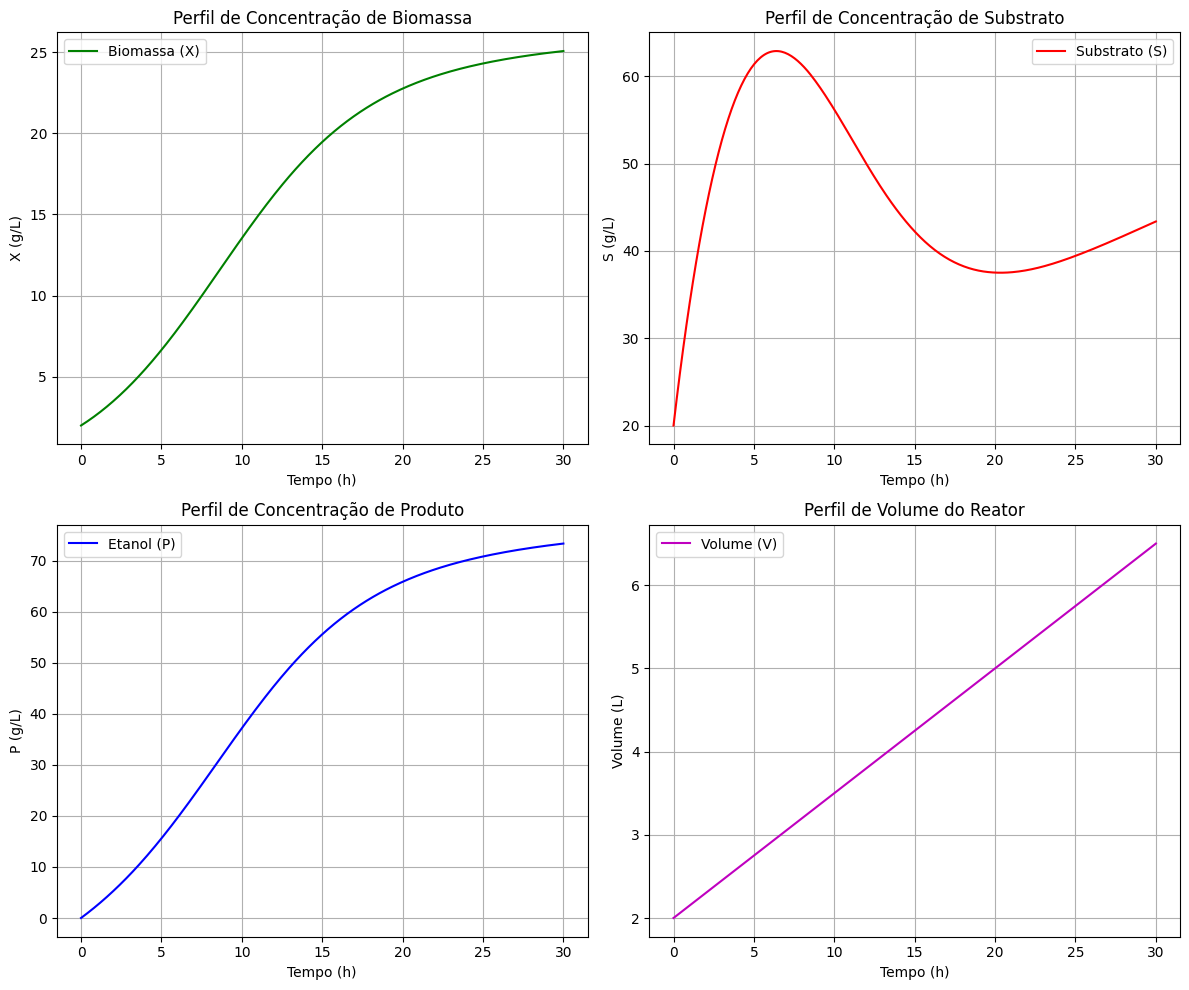

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# 1. Parâmetros Cinéticos (Andrews-Levenspiel) e Estequiométricos
mu_max = 0.45      # Taxa de crescimento específica máxima (1/h)
Ks = 0.5           # Constante de saturação do substrato (g/L)
Ki = 150.0         # Constante de inibição pelo substrato (g/L) [Termo de Andrews]
P_star = 90.0      # Concentração limite de produto que cessa o crescimento (g/L) [Termo de Levenspiel]
n = 1.5            # Expoente de Levenspiel

Y_xs = 0.15        # Coeficiente de rendimento de biomassa por substrato (g/g)
Y_ps = 0.45        # Coeficiente de rendimento de produto por substrato (g/g)
ms = 0.02          # Coeficiente de manutenção celular (g/g*h)

# Parâmetros de Alimentação (Fed-Batch)
F = 0.15           # Vazão de alimentação constante (L/h)
Sf = 300.0         # Concentração de substrato na alimentação (g/L)

# 2. Modelo de Equações Diferenciais Ordinárias (EDOs)
def fed_batch_model(t, y):
    X, S, P, V = y

    # Evitar valores negativos numéricos durante a integração
    X = max(X, 0.0)
    S = max(S, 0.0)
    P = max(P, 0.0)

    # Cinética de Andrews-Levenspiel para mu
    if S > 0 and P < P_star:
        andrews_term = S / (Ks + S + (S**2 / Ki))
        levenspiel_term = (1.0 - (P / P_star))**n
        mu = mu_max * andrews_term * levenspiel_term
    else:
        mu = 0.0

    # Taxas específicas de consumo e produção
    q_s = (mu / Y_xs) + ms
    q_p = mu * (Y_ps / Y_xs)

    # Balanços de Massa (Mecanísticos)
    # d(XV)/dt = mu*X*V  ->  dX/dt = (mu - F/V)*X
    dXdt = (mu - (F / V)) * X

    # d(SV)/dt = F*Sf - q_s*X*V -> dS/dt = (F/V)*(Sf - S) - q_s*X
    dSdt = (F / V) * (Sf - S) - (q_s * X)

    # d(PV)/dt = q_p*X*V -> dP/dt = q_p*X - (F/V)*P
    dPdt = (q_p * X) - ((F / V) * P)

    # dV/dt = F
    dVdt = F

    return [dXdt, dSdt, dPdt, dVdt]

# 3. Condições Iniciais e Tempo de Simulação
t_span = (0, 30)   # Tempo de 0 a 30 horas
t_eval = np.linspace(0, 30, 300)

X0 = 2.0           # Biomassa inicial (g/L)
S0 = 20.0          # Substrato inicial (g/L)
P0 = 0.0           # Produto inicial (g/L)
V0 = 2.0           # Volume inicial (L)

y0 = [X0, S0, P0, V0]

# Executar integração
sol = solve_ivp(fed_batch_model, t_span, y0, t_eval=t_eval, method='Radau')

# 4. Plotagem dos Resultados
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Biomassa
axs[0, 0].plot(sol.t, sol.y[0], 'g-', label='Biomassa (X)')
axs[0, 0].set_title('Perfil de Concentração de Biomassa')
axs[0, 0].set_xlabel('Tempo (h)')
axs[0, 0].set_ylabel('X (g/L)')
axs[0, 0].grid(True)
axs[0, 0].legend()

# Substrato
axs[0, 1].plot(sol.t, sol.y[1], 'r-', label='Substrato (S)')
axs[0, 1].set_title('Perfil de Concentração de Substrato')
axs[0, 1].set_xlabel('Tempo (h)')
axs[0, 1].set_ylabel('S (g/L)')
axs[0, 1].grid(True)
axs[0, 1].legend()

# Produto
axs[1, 0].plot(sol.t, sol.y[2], 'b-', label='Etanol (P)')
axs[1, 0].set_title('Perfil de Concentração de Produto')
axs[1, 0].set_xlabel('Tempo (h)')
axs[1, 0].set_ylabel('P (g/L)')
axs[1, 0].grid(True)
axs[1, 0].legend()

# Volume
axs[1, 1].plot(sol.t, sol.y[3], 'm-', label='Volume (V)')
axs[1, 1].set_title('Perfil de Volume do Reator')
axs[1, 1].set_xlabel('Tempo (h)')
axs[1, 1].set_ylabel('Volume (L)')
axs[1, 1].grid(True)
axs[1, 1].legend()

plt.tight_layout()
plt.show()